In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the 'taxis' dataset
df = sns.load_dataset("taxis")
df.head()

Matplotlib is building the font cache; this may take a moment.


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [2]:
# Check for missing values
print("Missing values before imputation:\n", df.isnull().sum())

# Impute missing values for numerical columns (using median)
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# Impute missing values for categorical columns (using mode)
categorical_cols = df.select_dtypes(include=['object', 'category']).columns
for col in categorical_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

# Remove rows for critical columns if any remain missing
df.dropna(subset=['pickup_borough', 'dropoff_borough'], inplace=True)
print("\nMissing values after imputation:\n", df.isnull().sum())

Missing values before imputation:
 pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

Missing values after imputation:
 pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


C:\Users\HP\AppData\Local\Temp\ipykernel_8284\2345637691.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object', 'category']).columns
C:\Users\HP\AppData\Local\Temp\ipykernel_8284\2345637691.py:16: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(subset=['pickup_borough', 'dropoff_borough'], inplace=True)


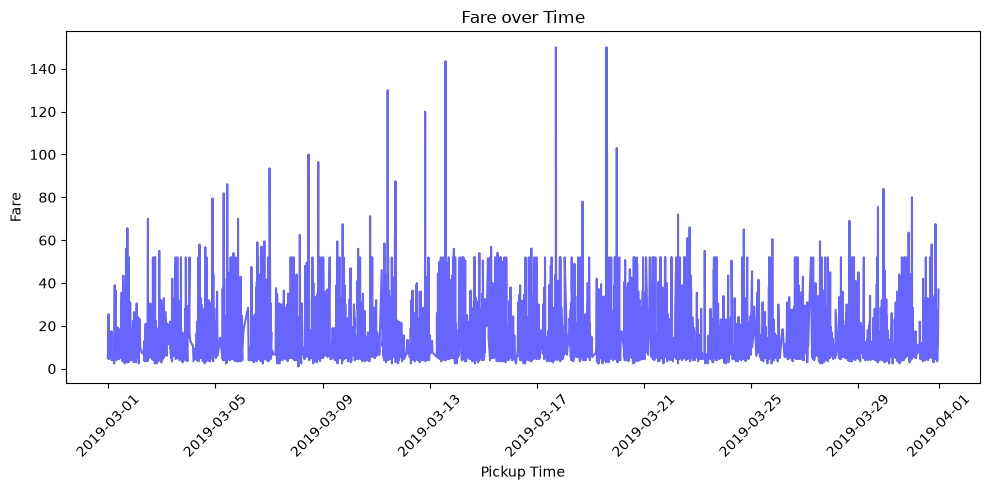

In [3]:
df['pickup'] = pd.to_datetime(df['pickup'])
df_sorted = df.sort_values('pickup')

plt.figure(figsize=(10, 5))
plt.plot(df_sorted['pickup'], df_sorted['fare'], color='blue', alpha=0.6)
plt.title('Fare over Time')
plt.xlabel('Pickup Time')
plt.ylabel('Fare')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

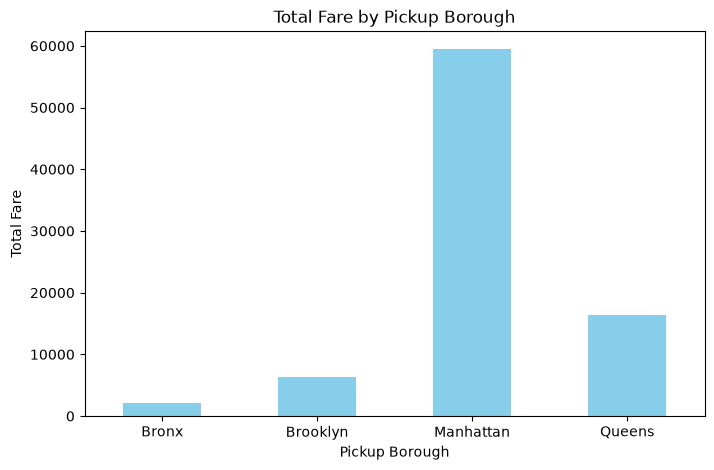

In [4]:
plt.figure(figsize=(8, 5))
borough_fare = df.groupby('pickup_borough')['fare'].sum()
borough_fare.plot(kind='bar', color='skyblue')
plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')
plt.xticks(rotation=0)
plt.show()

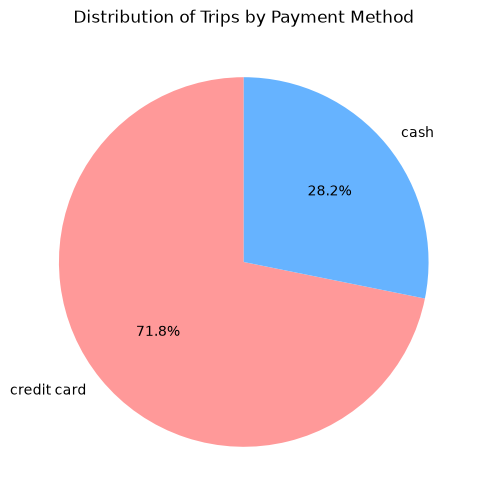

In [5]:
plt.figure(figsize=(6, 6))
payment_counts = df['payment'].value_counts()
payment_counts.plot(kind='pie', autopct='%1.1f%%', startangle=90, colors=['#ff9999','#66b3ff'])
plt.title('Distribution of Trips by Payment Method')
plt.ylabel('') 
plt.show()

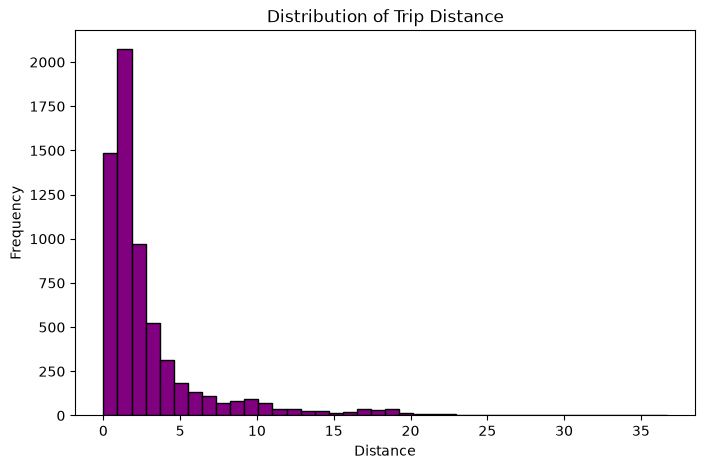

In [6]:
plt.figure(figsize=(8, 5))
df['distance'].plot(kind='hist', bins=40, color='purple', edgecolor='black')
plt.title('Distribution of Trip Distance')
plt.xlabel('Distance')
plt.show()

<Figure size 800x500 with 0 Axes>

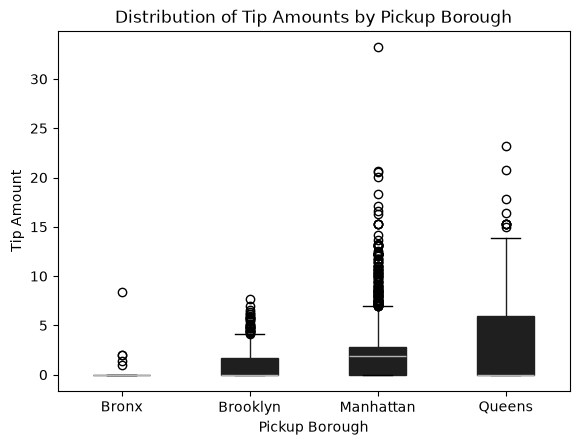

In [7]:
plt.figure(figsize=(8, 5))
df.boxplot(column='tip', by='pickup_borough', grid=False, patch_artist=True)
plt.title('Distribution of Tip Amounts by Pickup Borough')
plt.suptitle('') 
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_8284\2168559232.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='pickup_borough', palette='Set2')


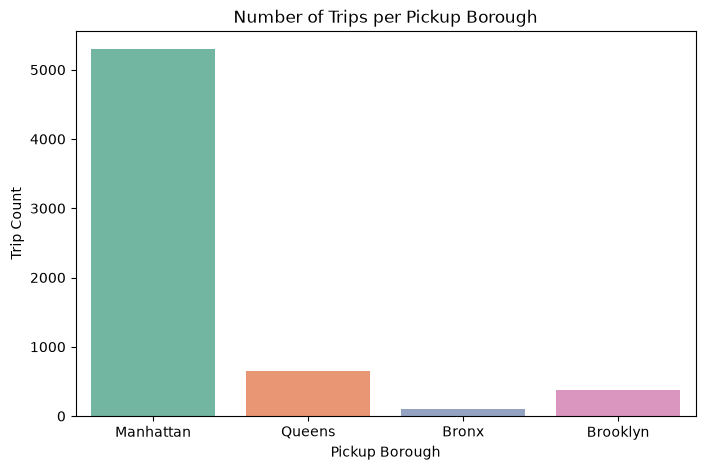

In [8]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='pickup_borough', palette='Set2')
plt.title('Number of Trips per Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Trip Count')
plt.show()

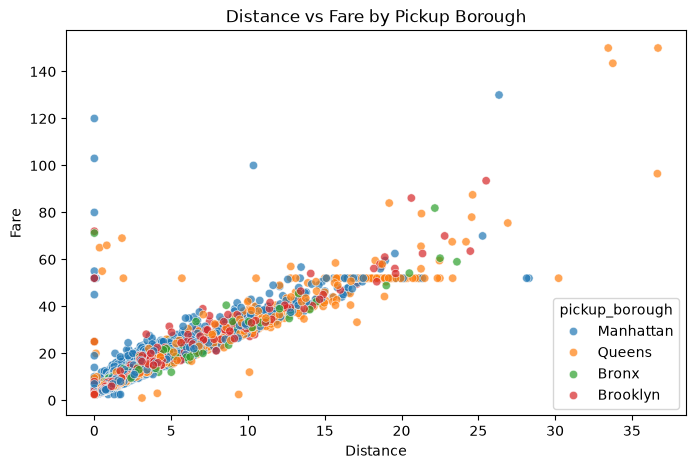

In [9]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='distance', y='fare', hue='pickup_borough', alpha=0.7)
plt.title('Distance vs Fare by Pickup Borough')
plt.xlabel('Distance')
plt.ylabel('Fare')
plt.show()

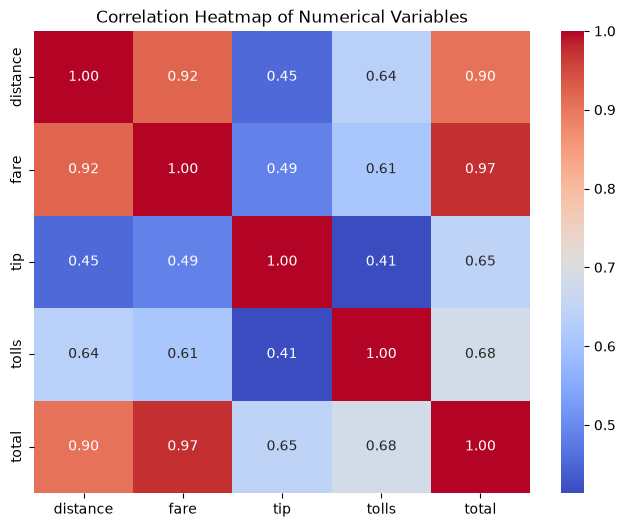

In [10]:
plt.figure(figsize=(8, 6))
numeric_subset = df[['distance', 'fare', 'tip', 'tolls', 'total']]
sns.heatmap(numeric_subset.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap of Numerical Variables')
plt.show()

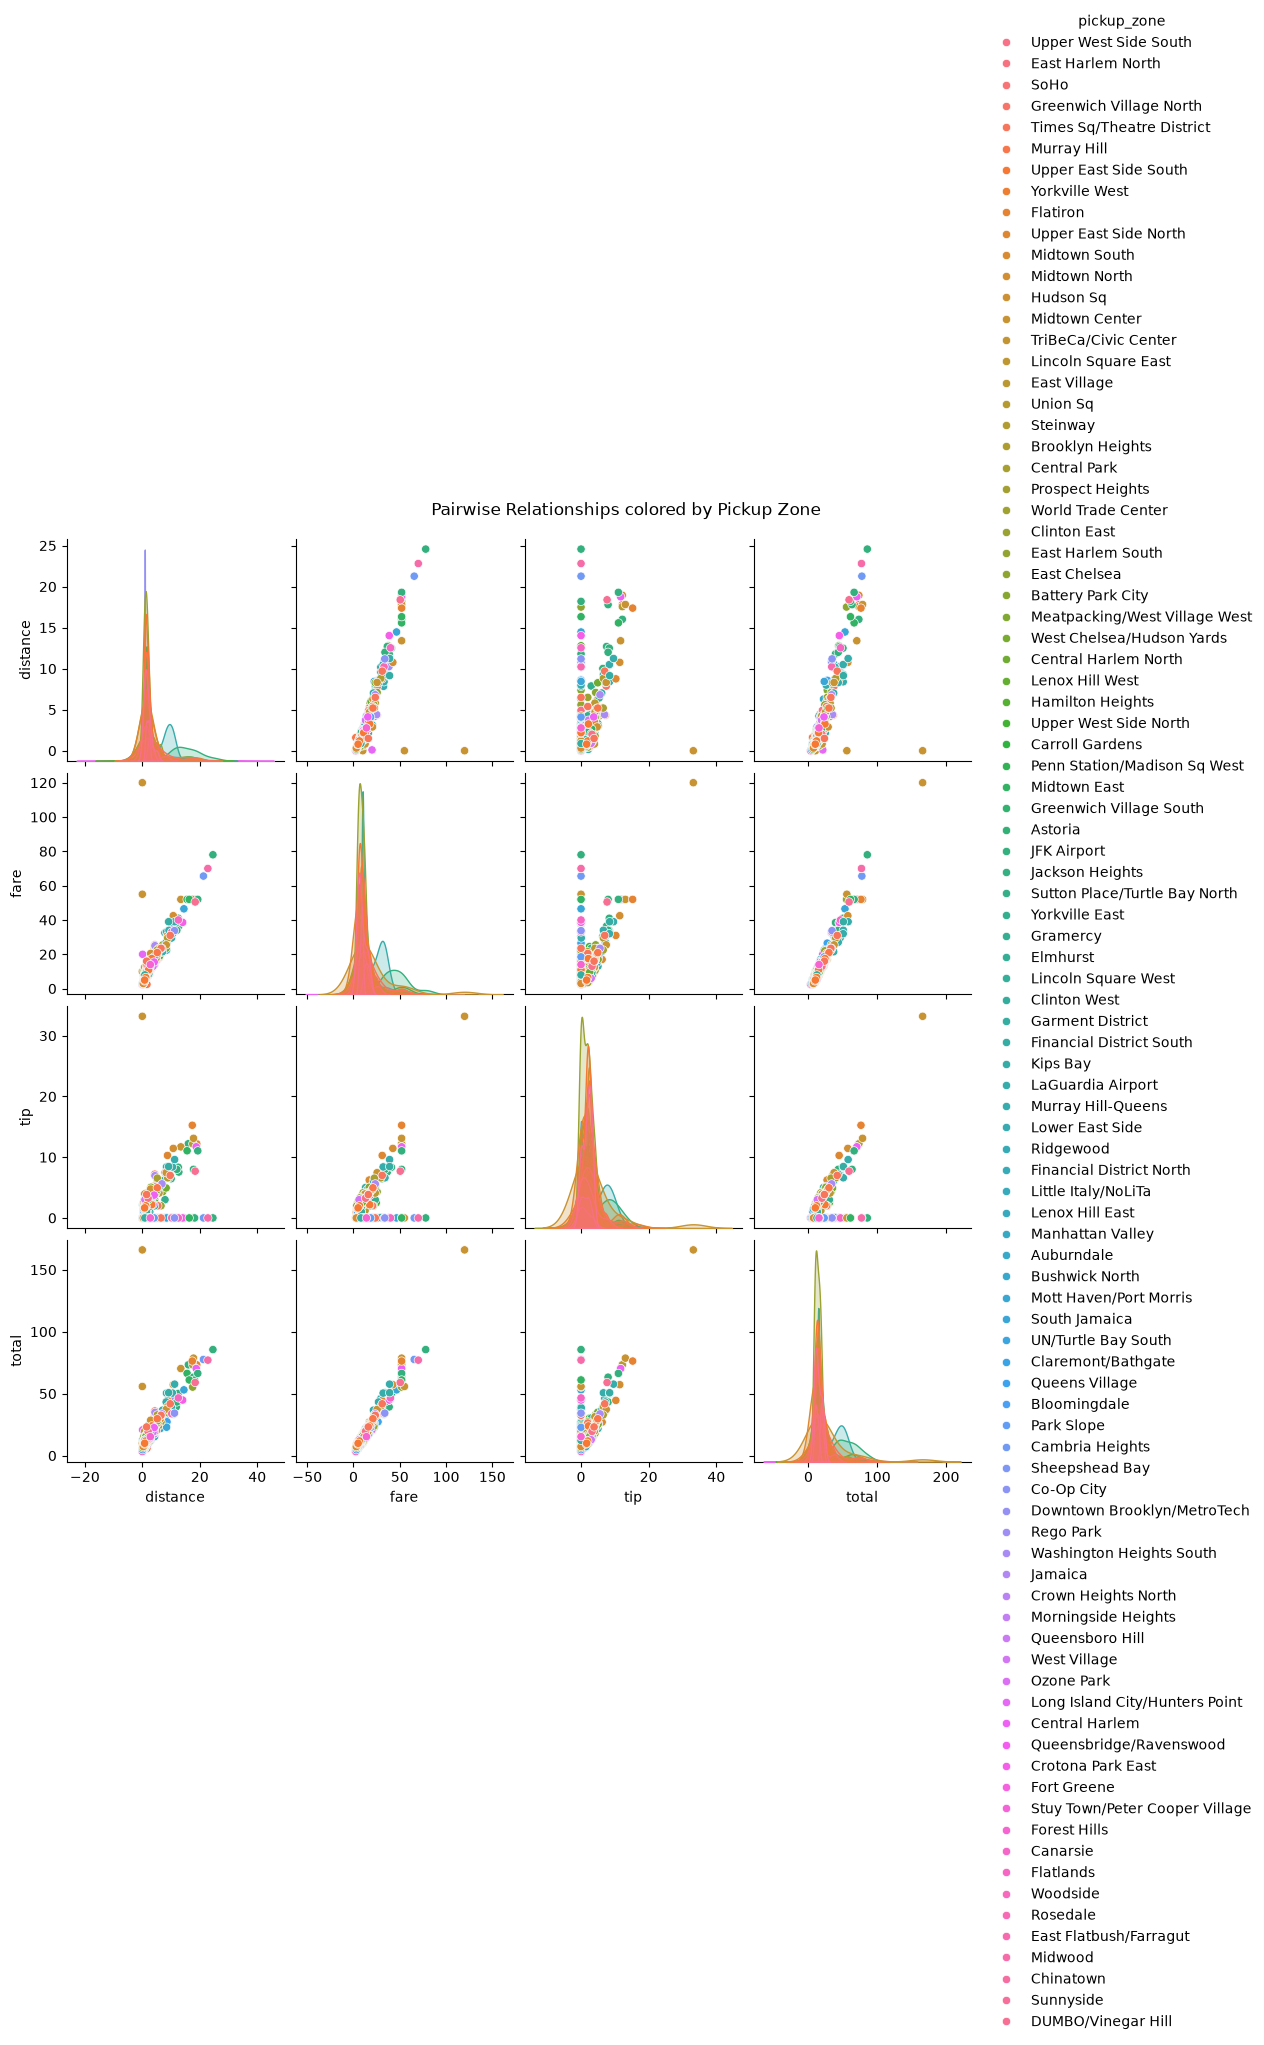

In [11]:
# Using a sample of 500 rows for faster rendering
sample_df = df[['distance', 'fare', 'tip', 'total', 'pickup_zone']].dropna().sample(n=500, random_state=42)
sns.pairplot(sample_df, hue='pickup_zone', diag_kind='kde')
plt.suptitle('Pairwise Relationships colored by Pickup Zone', y=1.02)
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_8284\2609290794.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='payment', y='fare', palette='muted')


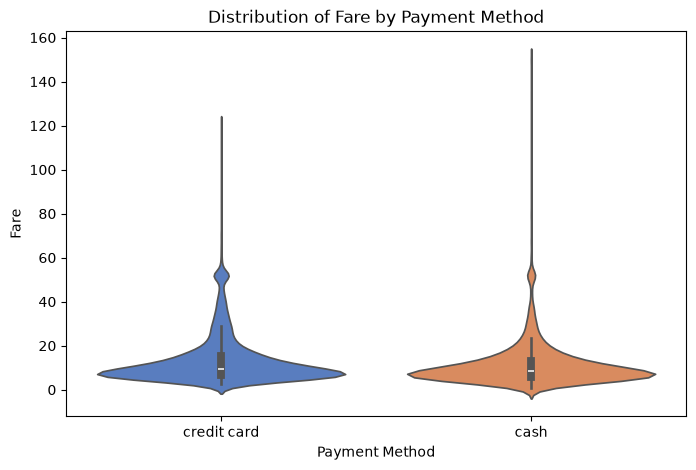

In [12]:
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x='payment', y='fare', palette='muted')
plt.title('Distribution of Fare by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare')
plt.show()